# Лекция. CUPED


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt

rng = np.random.default_rng(42)

pd.options.display.float_format = '{:,.4f}'.format

## 1. Генерируем данные эксперимента

У каждого пользователя будет:

- `x_pre` - значение похожей метрики до эксперимента;
- `y` - метрика в эксперименте;
- `variant` - контроль или тест.

Важно: `x_pre` измерен **до** назначения пользователя в вариант, поэтому он не может быть эффектом теста.

In [2]:
n_per_group = 10_000
n = 2 * n_per_group

variant = np.array(['control'] * n_per_group + ['treatment'] * n_per_group)

x_pre = rng.lognormal(mean=2.0, sigma=0.8, size=n) # денежные метрики обычно имеют более тяжелый правый хвост

noise = rng.normal(loc=0.0, scale=4.0, size=n)

true_effect = 0.35
is_treatment = (variant == 'treatment').astype(int)

y = 4.0 + 0.7 * x_pre + true_effect * is_treatment + noise

df = pd.DataFrame({
    'user_id': np.arange(1, n + 1),
    'variant': variant,
    'x_pre': x_pre,
    'y': y,
})

df.head()

,user_id,variant,x_pre,y
0,1,control,9.4288,3.9674
1,2,control,3.2156,9.8157
2,3,control,13.4686,13.1959
3,4,control,15.6810,12.5771
4,5,control,1.5514,4.0827


## 2. Проверяем, что covariate измерен до эксперимента и сбалансирован

CUPED не требует идеального равенства `x_pre` в группах, но большие различия в pre-period метрике - красный флаг для рандомизации или логирования.

In [3]:
summary = (
    df
    .groupby('variant')
    .agg(
        users=('user_id', 'count'),
        mean_x_pre=('x_pre', 'mean'),
        mean_y=('y', 'mean'),
        var_y=('y', 'var')
    )
)
summary

,users,mean_x_pre,mean_y,var_y
variant,,,,
control,10000,10.1386,11.1547,61.8551
treatment,10000,10.3567,11.5722,62.1293


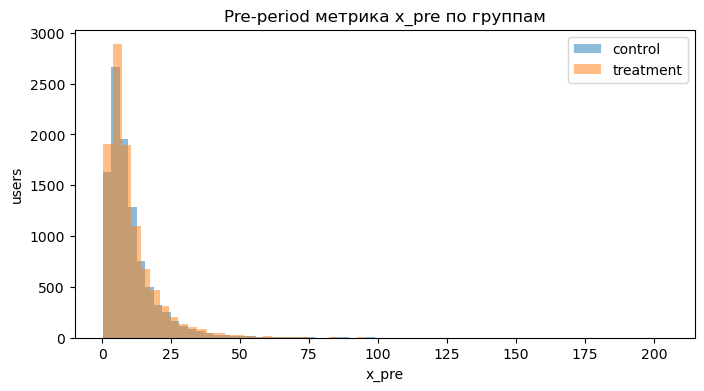

In [4]:
plt.figure(figsize=(8, 4))
plt.hist(df.loc[df['variant'] == 'control', 'x_pre'], bins=60, alpha=0.5, label='control')
plt.hist(df.loc[df['variant'] == 'treatment', 'x_pre'], bins=60, alpha=0.5, label='treatment')
plt.title('Pre-period метрика x_pre по группам')
plt.xlabel('x_pre')
plt.ylabel('users')
plt.legend()
plt.show()

## 3. Baseline: обычная оценка эффекта

До CUPED считаем стандартную разницу средних:

$$
\widehat{\tau}
=
\bar{Y}_{\mathrm{treatment}}
-
\bar{Y}_{\mathrm{control}}
$$

и стандартную ошибку:

$$
\operatorname{SE}(\widehat{\tau})
=
\sqrt{
\frac{s_{\mathrm{treatment}}^2}{n_{\mathrm{treatment}}}
+
\frac{s_{\mathrm{control}}^2}{n_{\mathrm{control}}}
}
$$

In [6]:
control_y = df.loc[df['variant'] == 'control', 'y']
treatment_y = df.loc[df['variant'] == 'treatment', 'y']

mean_control = control_y.mean()
mean_treatment = treatment_y.mean()

baseline_effect = mean_treatment - mean_control

var_control = control_y.var(ddof=1)
var_treatment = treatment_y.var(ddof=1)

n_control = control_y.shape[0]
n_treatment = treatment_y.shape[0]

baseline_se = sqrt(var_control / n_control + var_treatment / n_treatment)
baseline_ci_left = baseline_effect - 1.96 * baseline_se
baseline_ci_right = baseline_effect + 1.96 * baseline_se

pd.DataFrame({
    'estimate': [baseline_effect],
    'standard_error': [baseline_se],
    'ci_left_95': [baseline_ci_left],
    'ci_right_95': [baseline_ci_right]
}, index=['baseline'])

,estimate,standard_error,ci_left_95,ci_right_95
baseline,0.4175,0.1113,0.1992,0.6357


## 4. Идея CUPED

Мы хотим заменить исходную метрику $Y$ на скорректированную метрику:

$$
Y_{\mathrm{CUPED}}
=
Y
-
\theta\left(X-\bar{X}\right)
$$

где коэффициент коррекции равен

$$
\theta
=
\frac{
\operatorname{Cov}(Y, X)
}{
\operatorname{Var}(X)
}
$$

Здесь:

- $Y$ — метрика пользователя во время эксперимента;
- $X$ — значение связанной метрики до начала эксперимента;
- $\bar{X}$ — среднее значение $X$ по выборке;
- $\theta$ — коэффициент, определяющий величину CUPED-коррекции.

Интуиция следующая: если пользователь и до эксперимента был «крупным», то часть его высокого значения $Y$ объясняется не воздействием эксперимента, а его обычным уровнем активности.

CUPED использует $X$, чтобы оценить эту предсказуемую часть, и вычитает ее из исходной метрики.

In [7]:
x_centered = df['x_pre'] - df['x_pre'].mean()
y_centered = df['y'] - df['y'].mean()

cov_y_x = (x_centered * y_centered).sum() / (len(df) - 1)
var_x = (x_centered ** 2).sum() / (len(df) - 1)

theta = cov_y_x / var_x

print('Cov(Y, X) =', round(cov_y_x, 4))
print('Var(X)    =', round(var_x, 4))
print('theta     =', round(theta, 4))

Cov(Y, X) = 65.68
Var(X)    = 94.0295
theta     = 0.6985


In [8]:
df['y_cuped'] = df['y'] - theta * (df['x_pre'] - df['x_pre'].mean())

variance_comparison = pd.DataFrame({
    'metric': ['y', 'y_cuped'],
    'variance': [df['y'].var(ddof=1), df['y_cuped'].var(ddof=1)]
})
variance_comparison['variance_reduction'] = 1 - variance_comparison['variance'] / variance_comparison.loc[0, 'variance']
variance_comparison

,metric,variance,variance_reduction
0,y,62.0327,0.0000
1,y_cuped,16.1549,0.7396


## 5. Эффект после CUPED

Теперь считаем A/B-эффект ровно так же, но используем `y_cuped` вместо `y`.

In [9]:
control_cuped = df.loc[df['variant'] == 'control', 'y_cuped']
treatment_cuped = df.loc[df['variant'] == 'treatment', 'y_cuped']

cuped_effect = treatment_cuped.mean() - control_cuped.mean()

cuped_var_control = control_cuped.var(ddof=1)
cuped_var_treatment = treatment_cuped.var(ddof=1)

cuped_se = sqrt(cuped_var_control / n_control + cuped_var_treatment / n_treatment)
cuped_ci_left = cuped_effect - 1.96 * cuped_se
cuped_ci_right = cuped_effect + 1.96 * cuped_se

result = pd.DataFrame({
    'estimate': [baseline_effect, cuped_effect],
    'standard_error': [baseline_se, cuped_se],
    'ci_left_95': [baseline_ci_left, cuped_ci_left],
    'ci_right_95': [baseline_ci_right, cuped_ci_right],
}, index=['baseline', 'cuped'])

result['se_reduction'] = 1 - result['standard_error'] / result.loc['baseline', 'standard_error']
result

,estimate,standard_error,ci_left_95,ci_right_95,se_reduction
baseline,0.4175,0.1113,0.1992,0.6357,0.0000
cuped,0.2652,0.0568,0.1538,0.3765,0.4898


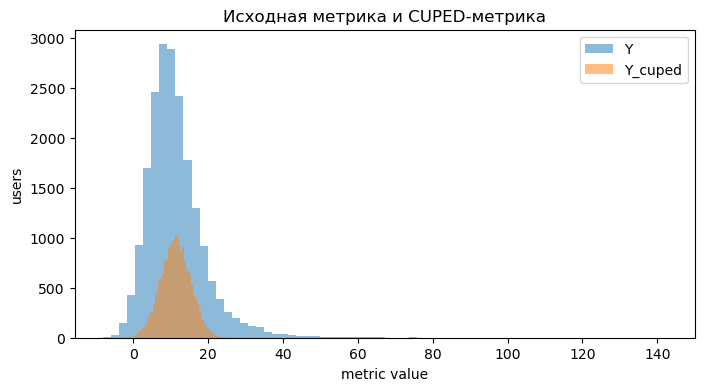

In [10]:
plt.figure(figsize=(8, 4))
plt.hist(df['y'], bins=70, alpha=0.5, label='Y')
plt.hist(df['y_cuped'], bins=70, alpha=0.5, label='Y_cuped')
plt.title('Исходная метрика и CUPED-метрика')
plt.xlabel('metric value')
plt.ylabel('users')
plt.legend()
plt.show()

## 6. Почему эффект не ломается

Если `X` измерен до эксперимента, то рандомизация делает распределение `X` одинаковым в control и treatment в ожидании.

Поэтому вычитание `theta * (X - mean(X))` не добавляет систематический сдвиг в одну группу. Оно в основном убирает шум, связанный с индивидуальными различиями пользователей.

In [11]:
adjustment = theta * (df['x_pre'] - df['x_pre'].mean())
df['adjustment'] = adjustment

adjustment_diff = (
    df.loc[df['variant'] == 'treatment', 'adjustment'].mean()
    - df.loc[df['variant'] == 'control', 'adjustment'].mean()
)

print('Разница средних adjustment между группами:', round(adjustment_diff, 6))
print('Baseline effect:', round(baseline_effect, 6))
print('CUPED effect:   ', round(cuped_effect, 6))

Разница средних adjustment между группами: 0.152303
Baseline effect: 0.417483
CUPED effect:    0.26518


## 7. Насколько CUPED может помочь

Теоретически, если $X$ и $Y$ имеют корреляцию $\rho$, то дисперсия CUPED-метрики связана с исходной дисперсией примерно так:

$$
\frac{
\operatorname{Var}\left(Y_{\mathrm{CUPED}}\right)
}{
\operatorname{Var}(Y)
}
\approx
1-\rho^2
$$

То есть относительное снижение дисперсии составляет примерно:

$$
\rho^2
$$

Чем выше корреляция pre-period метрики $X$ с целевой метрикой $Y$, тем сильнее CUPED может уменьшить дисперсию.

Например:

- при $\rho = 0.1$ снижение дисперсии составляет примерно $1\%$;
- при $\rho = 0.5$ — примерно $25\%$;
- при $\rho = 0.8$ — примерно $64\%$.

In [12]:
rho = df['x_pre'].corr(df['y'])
theoretical_variance_ratio = 1 - rho ** 2
actual_variance_ratio = df['y_cuped'].var(ddof=1) / df['y'].var(ddof=1)

pd.DataFrame({
    'rho_corr_x_y': [rho],
    'theoretical_var_ratio_1_minus_rho2': [theoretical_variance_ratio],
    'actual_var_ratio': [actual_variance_ratio],
    'actual_variance_reduction': [1 - actual_variance_ratio]
})

,rho_corr_x_y,theoretical_var_ratio_1_minus_rho2,actual_var_ratio,actual_variance_reduction
0,0.8600,0.2604,0.2604,0.7396


## 8. Антипример: плохой covariate

Если взять признак, который почти не связан с `Y`, CUPED почти не даст выигрыша. Метод не магический: ему нужен предиктивный pre-period сигнал.

In [13]:
df['x_bad'] = rng.normal(size=len(df))

x_bad_centered = df['x_bad'] - df['x_bad'].mean()

cov_y_x_bad = (x_bad_centered * y_centered).sum() / (len(df) - 1)
var_x_bad = (x_bad_centered ** 2).sum() / (len(df) - 1)
theta_bad = cov_y_x_bad / var_x_bad

df['y_cuped_bad'] = df['y'] - theta_bad * (df['x_bad'] - df['x_bad'].mean())

pd.DataFrame({
    'metric': ['y', 'y_cuped_good_x', 'y_cuped_bad_x'],
    'corr_with_y_before_adjustment': [1.0, rho, df['x_bad'].corr(df['y'])],
    'variance': [df['y'].var(ddof=1), df['y_cuped'].var(ddof=1), df['y_cuped_bad'].var(ddof=1)]
})

,metric,corr_with_y_before_adjustment,variance
0,y,1.0000,62.0327
1,y_cuped_good_x,0.8600,16.1549
2,y_cuped_bad_x,0.0013,62.0326


## 9. Практический чеклист

1. Найти pre-period метрику `X`, измеренную до эксперимента.
2. Проверить, что `X` не может быть затронута treatment.
3. Проверить корреляцию `corr(X, Y)`.
4. Посчитать `theta = Cov(Y, X) / Var(X)` на объединенной выборке или на control.
5. Построить `Y_cuped = Y - theta * (X - mean(X))`.
6. Запустить обычный анализ A/B-теста на `Y_cuped`.
7. В отчете показать не только p-value, но и уменьшение SE/CI.

In [14]:
report = result.copy()
report['ci_width_95'] = report['ci_right_95'] - report['ci_left_95']
report['ci_width_reduction'] = 1 - report['ci_width_95'] / report.loc['baseline', 'ci_width_95']
report

,estimate,standard_error,ci_left_95,ci_right_95,se_reduction,ci_width_95,ci_width_reduction
baseline,0.4175,0.1113,0.1992,0.6357,0.0000,0.4365,0.0000
cuped,0.2652,0.0568,0.1538,0.3765,0.4898,0.2227,0.4898
